In [1]:
# Data manipulation
import pandas as pd
import numpy as np
from pathlib import Path

# Visualization
import matplotlib.pyplot as plt

# Evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay,
    precision_recall_curve,
    roc_curve
)

# Project configuration
TRAIN_YEAR = 2022
VALIDATION_YEAR = 2023
TEST_YEAR = 2024

print("Evaluation environment is ready.")
print(f"Training year: {TRAIN_YEAR}")
print(f"Validation year: {VALIDATION_YEAR}")
print(f"Final testing year: {TEST_YEAR}")

Evaluation environment is ready.
Training year: 2022
Validation year: 2023
Final testing year: 2024


In [2]:
# Prediction file locations
validation_folder = Path(
    r"C:\Users\bobmo\OneDrive\DataScience2\model_validation_predictions"
)

test_folder = Path(
    r"C:\Users\bobmo\OneDrive\DataScience2\2024_model_predictions"
)

# 2023 validation predictions
validation_files = {
    "Logistic Regression": validation_folder / "logreg_validation_predictions.parquet",
    "Random Forest": validation_folder / "rf_validation_predictions.parquet",
    "XGBoost": Path(
        r"C:\Users\bobmo\OneDrive\DataScience2\xgb_validation_predictions.parquet"
    ) / "xgb_validation_predictions.parquet"
}

# 2024 final testing predictions
test_files = {
    "Logistic Regression": test_folder / "logreg_test_2024_predictions.parquet",
    "Random Forest": test_folder / "rf_test_2024_predictions.parquet",
    "XGBoost": test_folder / "xgb_test_2024_predictions.parquet"
}

# Check that all prediction files exist
for model, file_path in {**validation_files, **test_files}.items():
    if not file_path.exists():
        raise FileNotFoundError(f"Missing prediction file: {file_path}")

print("All six prediction files were found.")

All six prediction files were found.


In [3]:
# Load validation predictions
logreg_checked = pd.read_parquet(
    validation_files["Logistic Regression"], engine="fastparquet"
)

rf_checked = pd.read_parquet(
    validation_files["Random Forest"], engine="fastparquet"
)

xgb_checked = pd.read_parquet(
    validation_files["XGBoost"], engine="fastparquet"
)

# Standardize the actual-label column
for predictions in [logreg_checked, rf_checked, xgb_checked]:
    predictions.rename(
        columns={"y_true": "y_test"},
        inplace=True
    )

# Display dataset information
validation_predictions = {
    "Logistic Regression": logreg_checked,
    "Random Forest": rf_checked,
    "XGBoost": xgb_checked
}

for model, predictions in validation_predictions.items():
    print(f"\n{model}")
    print("Shape:", predictions.shape)
    print("Columns:", predictions.columns.tolist())


Logistic Regression
Shape: (27655685, 8)
Columns: ['cell_id', 'weather_date', 'valid_time', 'y_test', 'y_prob', 'y_pred', 'model', 'threshold']

Random Forest
Shape: (27655685, 8)
Columns: ['cell_id', 'weather_date', 'valid_time', 'y_test', 'y_prob', 'y_pred', 'model', 'threshold']

XGBoost
Shape: (27655685, 8)
Columns: ['cell_id', 'weather_date', 'valid_time', 'y_test', 'y_prob', 'y_pred', 'model', 'threshold']


In [4]:
# VALIDATION DATA CHECKS

for model, df in validation_predictions.items():

    print(f"\n{'=' * 50}")
    print(model)
    print("=" * 50)

    print(f"Total observations: {len(df):,}")
    print(f"Wildfire observations: {(df['y_test'] == 1).sum():,}")
    print(f"Non-wildfire observations: {(df['y_test'] == 0).sum():,}")
    print(f"Missing values: {df.isnull().sum().sum():,}")
    print(
        "Duplicate observations:",
        df.duplicated(["cell_id", "valid_time"]).sum()
    )

    print(
        "Date range:",
        df["valid_time"].min(),
        "to",
        df["valid_time"].max()
    )


Logistic Regression
Total observations: 27,655,685
Wildfire observations: 3,668
Non-wildfire observations: 27,652,017
Missing values: 0
Duplicate observations: 0
Date range: 2023-01-01 00:00:00 to 2023-12-31 00:00:00

Random Forest
Total observations: 27,655,685
Wildfire observations: 3,668
Non-wildfire observations: 27,652,017
Missing values: 0
Duplicate observations: 0
Date range: 2023-01-01 00:00:00 to 2023-12-31 00:00:00

XGBoost
Total observations: 27,655,685
Wildfire observations: 3,668
Non-wildfire observations: 27,652,017
Missing values: 0
Duplicate observations: 0
Date range: 2023-01-01 00:00:00 to 2023-12-31 00:00:00


In [5]:
# Final thresholds selected using 2023 validation
thresholds = {
    "Logistic Regression": 0.018,
    "Random Forest": 0.180,
    "XGBoost": 0.690
}

results_2023 = []

for model, df in validation_predictions.items():

    threshold = thresholds[model]

    y_true = df["y_test"]
    y_prob = df["y_prob"]
    y_pred = (y_prob >= threshold).astype(int)

    results_2023.append({
        "Model": model,
        "Threshold": threshold,
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1 Score": f1_score(y_true, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_true, y_prob),
        "Average Precision": average_precision_score(y_true, y_prob)
    })

results_2023 = pd.DataFrame(results_2023)

display(results_2023.round(6).style.hide(axis="index"))

Model,Threshold,Precision,Recall,F1 Score,ROC-AUC,Average Precision
Logistic Regression,0.018000,0.026483,0.041985,0.032479,0.964564,0.010470
Random Forest,0.180000,0.404298,0.553980,0.467449,0.992233,0.449292
XGBoost,0.690000,0.308760,0.564068,0.399074,0.948203,0.267280


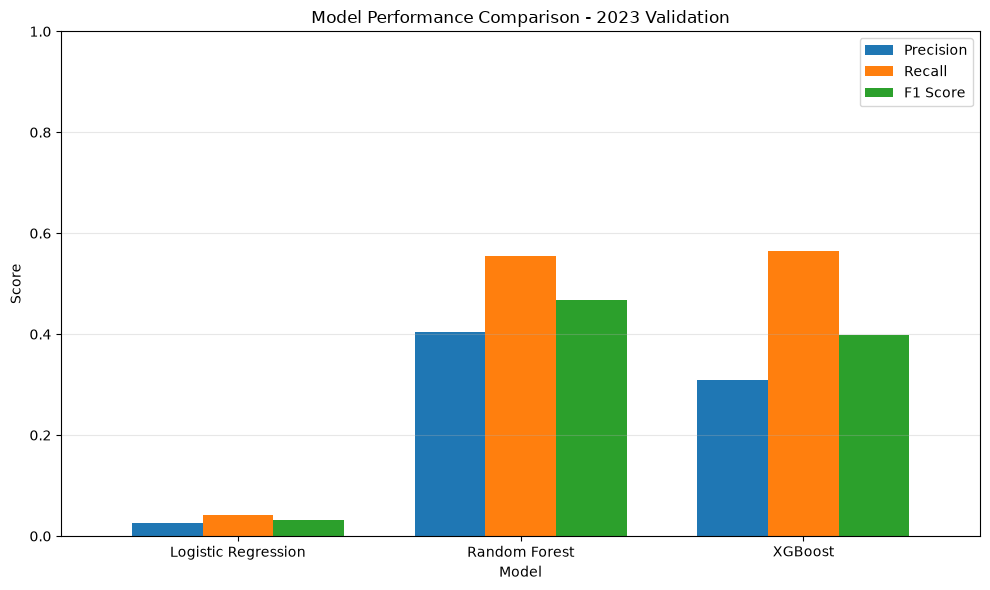

In [6]:
# VALIDATION METRICS COMPARISON

metrics = ["Precision", "Recall", "F1 Score"]

results_2023.set_index("Model")[metrics].plot(
    kind="bar",
    figsize=(10, 6),
    width=0.75
)

plt.title("Model Performance Comparison - 2023 Validation")
plt.ylabel("Score")
plt.xlabel("Model")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.legend(loc="upper right")
plt.tight_layout()
plt.show()

C:\Users\bobmo\AppData\Local\Temp\ipykernel_27368\1582709274.py:20: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.tight_layout()
C:\Users\bobmo\Anaconda3\envs\tensorflow\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


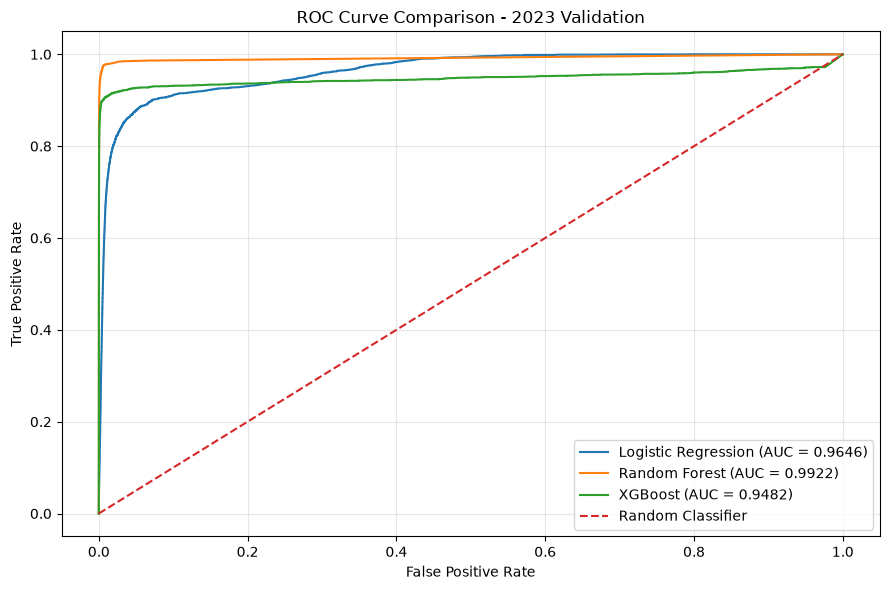

In [7]:
#ROC Curve Comparison
plt.figure(figsize=(9, 6))

for model, df in validation_predictions.items():
    y_true = df["y_test"]
    y_prob = df["y_prob"]

    fpr, tpr, _ = roc_curve(y_true, y_prob)
    auc = roc_auc_score(y_true, y_prob)

    plt.plot(fpr, tpr, label=f"{model} (AUC = {auc:.4f})")

plt.plot([0, 1], [0, 1], linestyle="--", label="Random Classifier")

plt.title("ROC Curve Comparison - 2023 Validation")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

C:\Users\bobmo\AppData\Local\Temp\ipykernel_27368\296270929.py:18: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.tight_layout()
C:\Users\bobmo\Anaconda3\envs\tensorflow\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


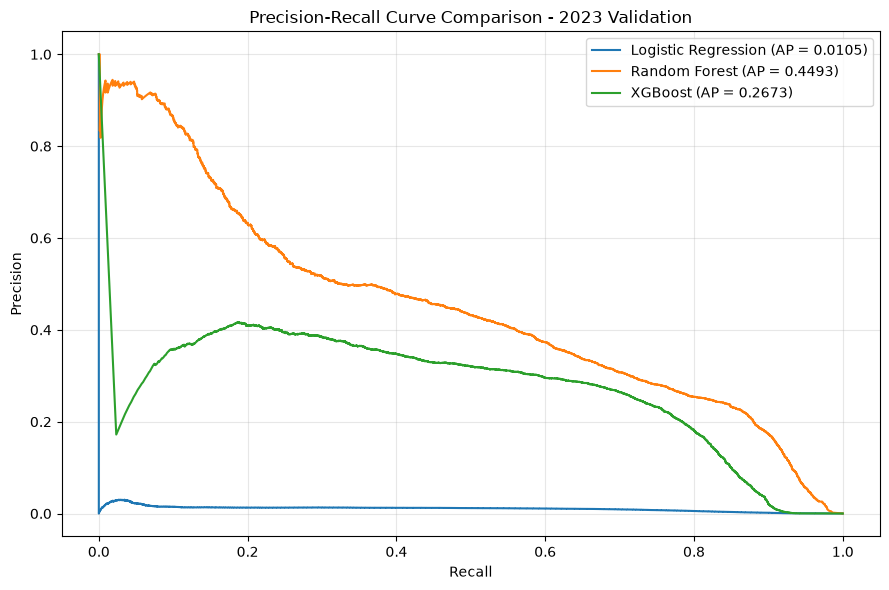

In [8]:
# Precision-Recall Curve Comparison
plt.figure(figsize=(9, 6))

for model, df in validation_predictions.items():
    y_true = df["y_test"]
    y_prob = df["y_prob"]

    precision, recall, _ = precision_recall_curve(y_true, y_prob)
    ap = average_precision_score(y_true, y_prob)

    plt.plot(recall, precision, label=f"{model} (AP = {ap:.4f})")

plt.title("Precision-Recall Curve Comparison - 2023 Validation")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [15]:
import gc

# Delete large datasets only if they exist
variables_to_clear = [
    "validation_predictions",
    "logreg_checked",
    "rf_checked",
    "xgb_checked",
    "logreg_test",
    "rf_test",
    "xgb_test"
]

for variable in variables_to_clear:
    if variable in globals():
        del globals()[variable]

gc.collect()

print("Memory cleanup completed.")

Memory cleanup completed.


In [16]:
# Load only the necessary columns to reduce memory usage
logreg_test = pd.read_parquet(
    test_files["Logistic Regression"],
    columns=["y_true", "y_prob"],
    engine="fastparquet"
)

rf_test = pd.read_parquet(
    test_files["Random Forest"],
    columns=["y_true", "y_prob"],
    engine="fastparquet"
)

xgb_test = pd.read_parquet(
    test_files["XGBoost"],
    columns=["y_true", "y_prob"],
    engine="fastparquet"
)

# Rename actual labels
for df in [logreg_test, rf_test, xgb_test]:
    df.rename(columns={"y_true": "y_test"}, inplace=True)

# Organize predictions
test_predictions = {
    "Logistic Regression": logreg_test,
    "Random Forest": rf_test,
    "XGBoost": xgb_test
}

for model, df in test_predictions.items():
    print(f"{model}: {df.shape}")

print("\n2024 test predictions loaded successfully.")

Logistic Regression: (27731454, 2)
Random Forest: (27731454, 2)
XGBoost: (27731454, 2)

2024 test predictions loaded successfully.


In [17]:
# Data Quality Checks
# Before evaluating the models, we verify the 2024 test predictions for missing values, duplicate observations, valid probability ranges, and class distribution.

for model, df in test_predictions.items():
    print(f"\n{model}")
    print("-" * 40)

    print("Total observations:", len(df))
    print("Positive observations:", (df["y_test"] == 1).sum())
    print("Negative observations:", (df["y_test"] == 0).sum())
    print("Missing values:", df.isnull().sum().sum())
    print("Probability range:",
          df["y_prob"].min(), "to", df["y_prob"].max())


Logistic Regression
----------------------------------------
Total observations: 27731454
Positive observations: 3843
Negative observations: 27727611
Missing values: 0
Probability range: 6.809684e-09 to 0.29644576

Random Forest
----------------------------------------
Total observations: 27731454
Positive observations: 3843
Negative observations: 27727611
Missing values: 0
Probability range: 0.0 to 0.570361589867758

XGBoost
----------------------------------------
Total observations: 27731454
Positive observations: 3843
Negative observations: 27727611
Missing values: 0
Probability range: 3.006636e-39 to 1.0


In [18]:
# Final Model Performance Evaluation
# Evaluate all three models on the unseen 2024 test dataset using the fixed thresholds selected during 2023 validation. We calculate accuracy, precision, recall, F1-score, ROC-AUC, and Average Precision.

results_2024 = []

for model, df in test_predictions.items():
    threshold = thresholds[model]

    y_true = df["y_test"]
    y_prob = df["y_prob"]
    y_pred = (y_prob >= threshold).astype(int)

    results_2024.append({
        "Model": model,
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred),
        "Recall": recall_score(y_true, y_pred),
        "F1 Score": f1_score(y_true, y_pred),
        "ROC-AUC": roc_auc_score(y_true, y_prob),
        "Average Precision": average_precision_score(y_true, y_prob)
    })

results_2024 = pd.DataFrame(results_2024)

display(results_2024.round(6).style.hide(axis="index"))

Model,Threshold,Accuracy,Precision,Recall,F1 Score,ROC-AUC,Average Precision
Logistic Regression,0.018000,0.999676,0.028043,0.039813,0.032907,0.965714,0.011955
Random Forest,0.180000,0.999830,0.414875,0.547229,0.471948,0.990964,0.445782
XGBoost,0.690000,0.999784,0.332920,0.558678,0.417217,0.945847,0.270442



Logistic Regression - Threshold: 0.018
[[27722308     5303]
 [    3690      153]]


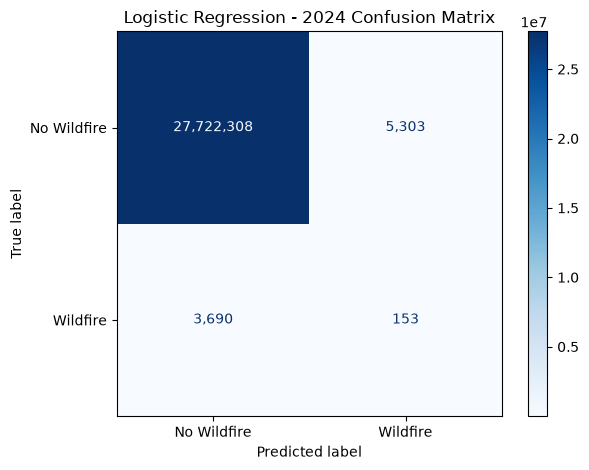


Random Forest - Threshold: 0.18
[[27724645     2966]
 [    1740     2103]]


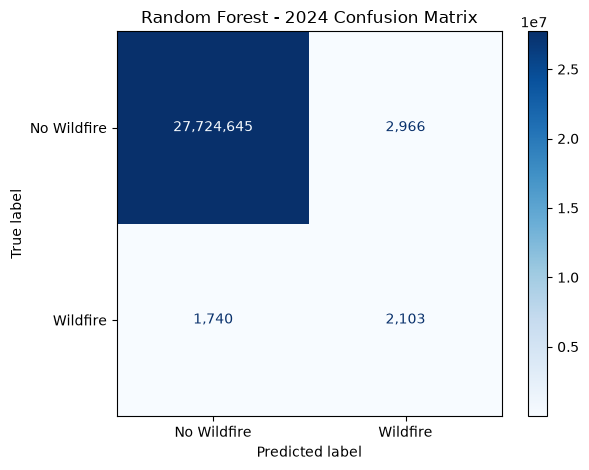


XGBoost - Threshold: 0.69
[[27723309     4302]
 [    1696     2147]]


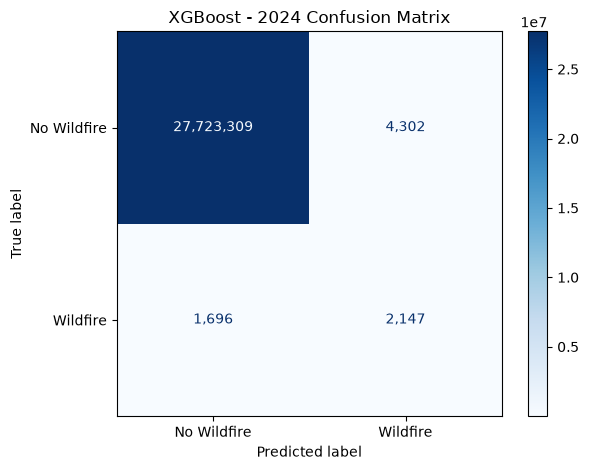

In [19]:
# Confusion Matrix Analysis
# Confusion matrices provide a detailed comparison between actual and predicted wildfire observations. They show true negatives, false positives, false negatives, and true positives for each model.

from sklearn.metrics import ConfusionMatrixDisplay

for model, df in test_predictions.items():
    threshold = thresholds[model]

    y_true = df["y_test"]
    y_pred = (df["y_prob"] >= threshold).astype(int)

    cm = confusion_matrix(y_true, y_pred)

    print(f"\n{model} - Threshold: {threshold}")
    print(cm)

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["No Wildfire", "Wildfire"]
    )

    disp.plot(cmap="Blues", values_format=",")
    plt.title(f"{model} - 2024 Confusion Matrix")
    plt.tight_layout()
    plt.show()

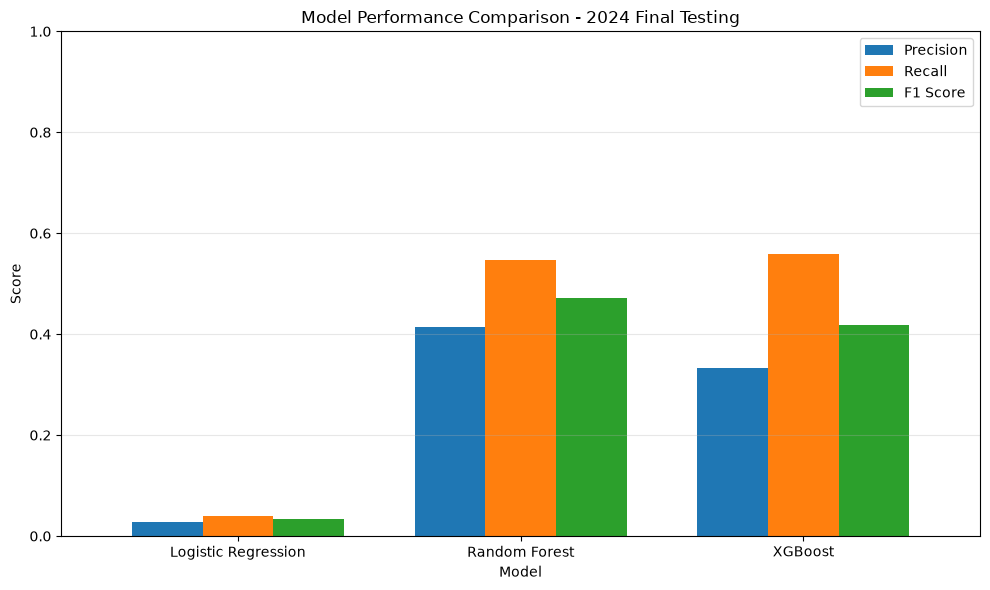

In [20]:
# Model Performance Visualizations
# Comparison of Precision, Recall, and F1-score

# Compare Precision, Recall, and F1-score on 2024 test data

metrics = ["Precision", "Recall", "F1 Score"]

results_2024.set_index("Model")[metrics].plot(
    kind="bar",
    figsize=(10, 6),
    width=0.75
)

plt.title("Model Performance Comparison - 2024 Final Testing")
plt.ylabel("Score")
plt.xlabel("Model")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.legend(loc="upper right")
plt.tight_layout()
plt.show()

C:\Users\bobmo\AppData\Local\Temp\ipykernel_27368\1810217936.py:21: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.tight_layout()
C:\Users\bobmo\Anaconda3\envs\tensorflow\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


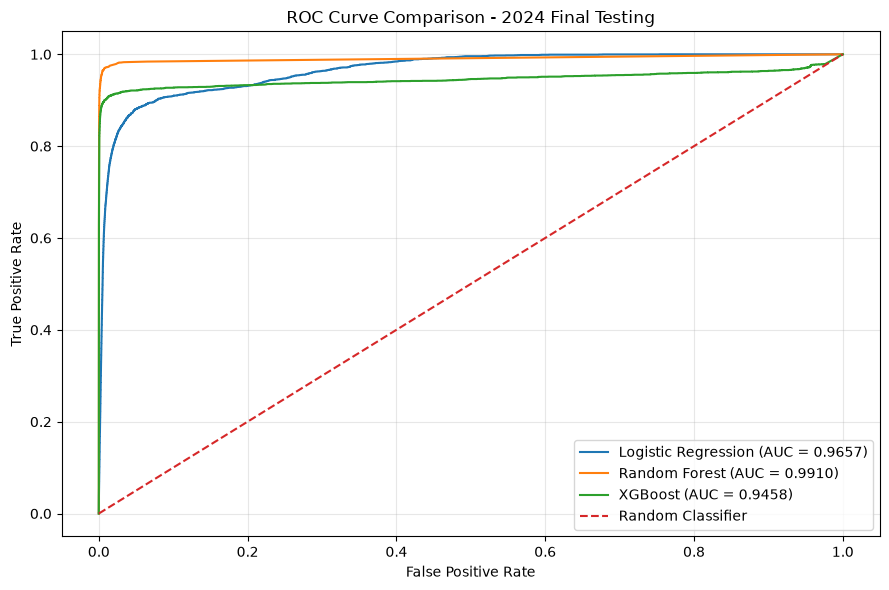

In [21]:
# ROC Curve Comparison

plt.figure(figsize=(9, 6))

for model, df in test_predictions.items():
    y_true = df["y_test"]
    y_prob = df["y_prob"]

    fpr, tpr, _ = roc_curve(y_true, y_prob)
    auc = roc_auc_score(y_true, y_prob)

    plt.plot(fpr, tpr, label=f"{model} (AUC = {auc:.4f})")

plt.plot([0, 1], [0, 1], linestyle="--", label="Random Classifier")

plt.title("ROC Curve Comparison - 2024 Final Testing")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

C:\Users\bobmo\AppData\Local\Temp\ipykernel_27368\2848518531.py:19: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.tight_layout()
C:\Users\bobmo\Anaconda3\envs\tensorflow\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


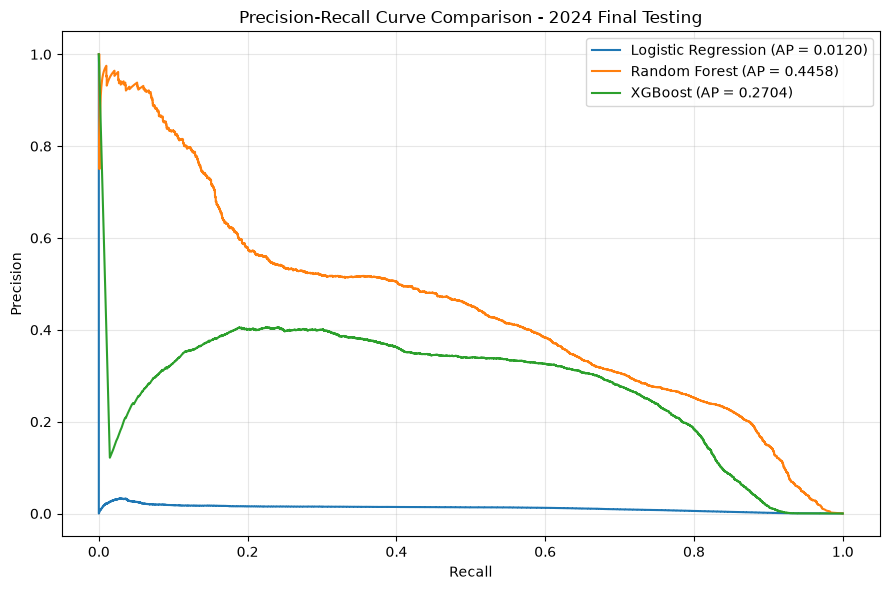

In [22]:
# Precision-Recall Curve Comparison

plt.figure(figsize=(9, 6))

for model, df in test_predictions.items():
    y_true = df["y_test"]
    y_prob = df["y_prob"]

    precision, recall, _ = precision_recall_curve(y_true, y_prob)
    ap = average_precision_score(y_true, y_prob)

    plt.plot(recall, precision, label=f"{model} (AP = {ap:.4f})")

plt.title("Precision-Recall Curve Comparison - 2024 Final Testing")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [23]:
# Comparison Between 2023 Validation and 2024 Final Testing
# This section compares model performance between the 2023 validation dataset and the unseen 2024 test dataset. The comparison helps assess model consistency and generalization across different years.

# Select the evaluation metrics for both years
metrics = [
    "Model",
    "Precision",
    "Recall",
    "F1 Score",
    "ROC-AUC",
    "Average Precision"
]

# Prepare 2023 and 2024 results
comparison_2023 = results_2023[metrics].copy()
comparison_2024 = results_2024[metrics].copy()

# Merge both years
comparison = comparison_2023.merge(
    comparison_2024,
    on="Model",
    suffixes=("_2023", "_2024")
)

# Display comparison
display(comparison.round(6).style.hide(axis="index"))

Model,Precision_2023,Recall_2023,F1 Score_2023,ROC-AUC_2023,Average Precision_2023,Precision_2024,Recall_2024,F1 Score_2024,ROC-AUC_2024,Average Precision_2024
Logistic Regression,0.026483,0.041985,0.032479,0.964564,0.010470,0.028043,0.039813,0.032907,0.965714,0.011955
Random Forest,0.404298,0.553980,0.467449,0.992233,0.449292,0.414875,0.547229,0.471948,0.990964,0.445782
XGBoost,0.308760,0.564068,0.399074,0.948203,0.267280,0.332920,0.558678,0.417217,0.945847,0.270442


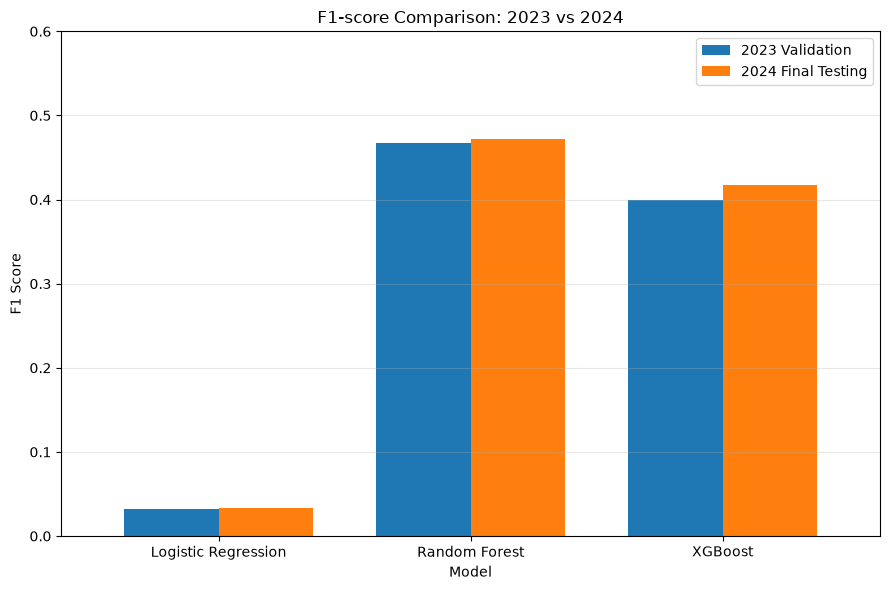

In [24]:
# F1-score Comparison Between 2023 and 2024

f1_comparison = comparison[
    ["Model", "F1 Score_2023", "F1 Score_2024"]
].set_index("Model")

f1_comparison.plot(
    kind="bar",
    figsize=(9, 6),
    width=0.75
)

plt.title("F1-score Comparison: 2023 vs 2024")
plt.ylabel("F1 Score")
plt.xlabel("Model")
plt.ylim(0, 0.6)
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.legend(["2023 Validation", "2024 Final Testing"])
plt.tight_layout()
plt.show()

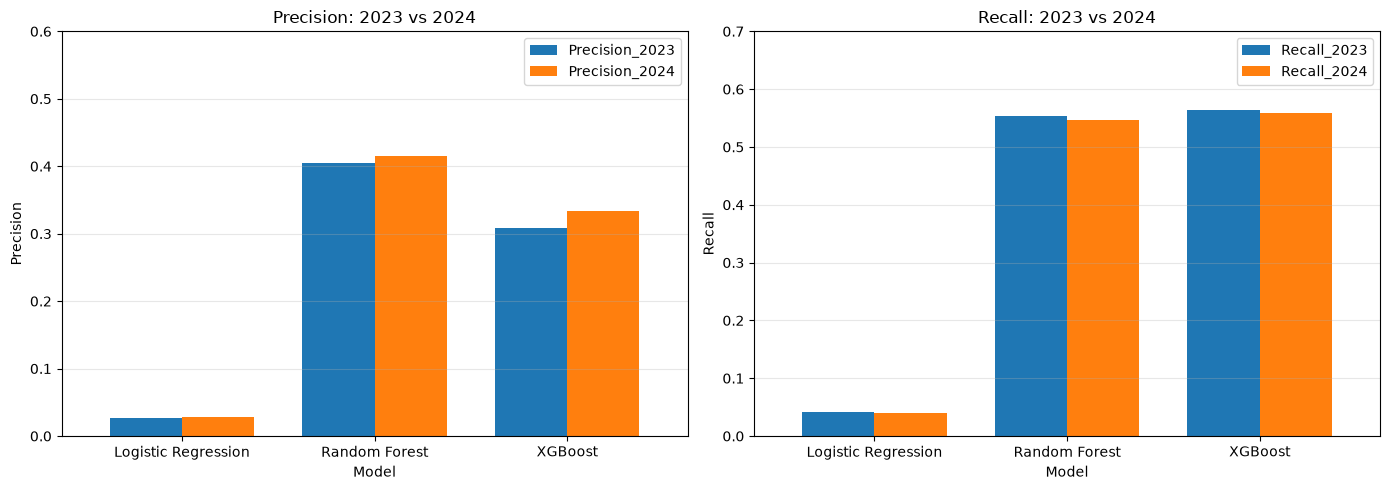

In [25]:
# Precision and Recall Comparison Between 2023 and 2024

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Precision comparison
comparison.set_index("Model")[
    ["Precision_2023", "Precision_2024"]
].plot(kind="bar", ax=axes[0], width=0.75)

axes[0].set_title("Precision: 2023 vs 2024")
axes[0].set_ylabel("Precision")
axes[0].set_ylim(0, 0.6)
axes[0].tick_params(axis="x", rotation=0)
axes[0].grid(axis="y", alpha=0.3)

# Recall comparison
comparison.set_index("Model")[
    ["Recall_2023", "Recall_2024"]
].plot(kind="bar", ax=axes[1], width=0.75)

axes[1].set_title("Recall: 2023 vs 2024")
axes[1].set_ylabel("Recall")
axes[1].set_ylim(0, 0.7)
axes[1].tick_params(axis="x", rotation=0)
axes[1].grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

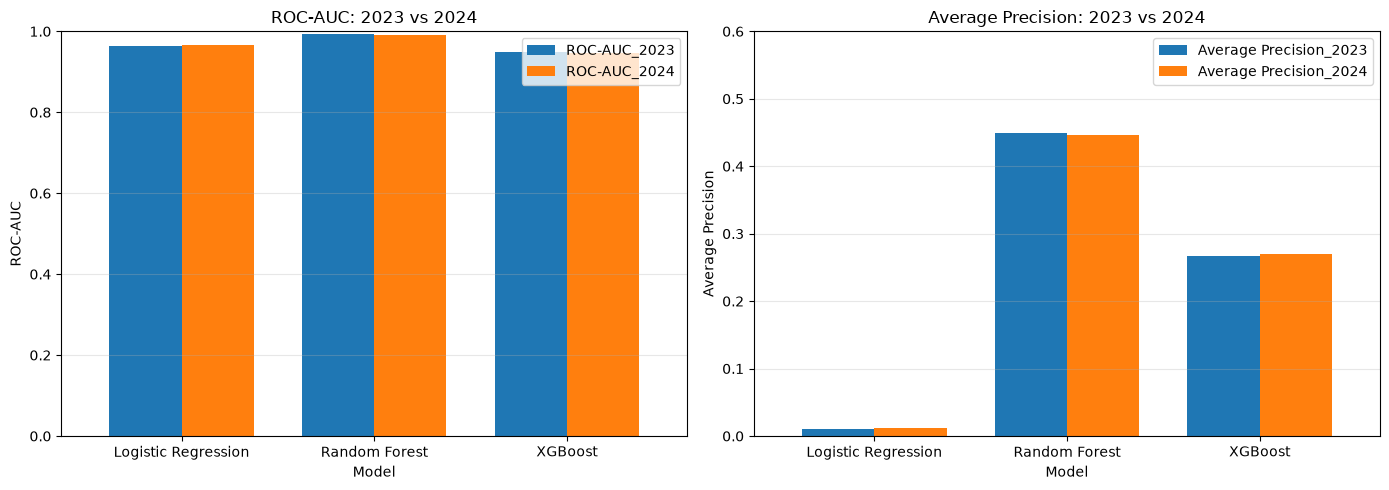

In [26]:
# ROC-AUC and Average Precision Comparison

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# ROC-AUC comparison
comparison.set_index("Model")[
    ["ROC-AUC_2023", "ROC-AUC_2024"]
].plot(kind="bar", ax=axes[0], width=0.75)

axes[0].set_title("ROC-AUC: 2023 vs 2024")
axes[0].set_ylabel("ROC-AUC")
axes[0].set_ylim(0, 1)
axes[0].tick_params(axis="x", rotation=0)
axes[0].grid(axis="y", alpha=0.3)

# Average Precision comparison
comparison.set_index("Model")[
    ["Average Precision_2023", "Average Precision_2024"]
].plot(kind="bar", ax=axes[1], width=0.75)

axes[1].set_title("Average Precision: 2023 vs 2024")
axes[1].set_ylabel("Average Precision")
axes[1].set_ylim(0, 0.6)
axes[1].tick_params(axis="x", rotation=0)
axes[1].grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
# Final Conclusions
# The evaluation compared Logistic Regression, Random Forest, and XGBoost using 2023 validation data and unseen 2024 test data. Random Forest achieved the strongest overall performance, maintaining the highest F1-score, ROC-AUC, and Average Precision in both years. XGBoost achieved the highest recall, making it a competitive alternative when identifying as many wildfire observations as possible is the priority. Logistic Regression demonstrated substantially weaker performance.
# Overall, Random Forest is the recommended model because it provides the best balance between precision and recall while maintaining consistent performance across both years. These results demonstrate its potential for wildfire prediction, although further improvements are needed to reduce false alarms and missed wildfire observations.

